# FD004 DS-B: Restricted Operating-Envelope Shift

## Objective
Evaluate the robustness of the frozen FD004 prognostics and uncertainty pipeline when predictions are made at the **edge/outside of the operating envelope** represented during training and calibration.

## How DS-B differs from DS-A
- **DS-A:** one complete operating regime is held out.
- **DS-B:** all six regimes remain represented, but training/calibration endpoints are restricted to the central operating envelope within each regime, while test endpoints lie outside that envelope.

## Primary DS-B definition
1. Split engines first into train / calibration / test groups.
2. Fit the six-regime representation using the same FD004 setup.
3. Within each regime, estimate operating-setting location and scale from **training engines only**.
4. Compute a normalized operating-envelope distance using the three operating settings.
5. Define the central envelope using the **80th percentile** of training-engine distance within each regime.
6. Train/calibrate only on windows whose prediction endpoint is inside the envelope.
7. Test only on unseen engines whose prediction endpoint lies outside the envelope.
8. Preserve complete 30-cycle temporal histories; endpoint eligibility determines the split.
9. Do not tune the model after viewing DS-B test results.

### Frozen Paper 1 configuration
- Dataset: NASA C-MAPSS FD004
- RUL clipping: 125 cycles
- Window length: 30 cycles
- 14 selected sensors
- 6 operating regimes
- Regime one-hot representation
- 20 input channels
- Dense(18, no bias) → BiLSTM(64) → temporal attention
- Quantiles: 0.10 / 0.50 / 0.90
- Target interval coverage: 80%
- Asymmetric CQR + Balanced Engine CQR
- Seed: 42

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Imports and constants

In [2]:
import os
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

DATA_DIR = "/content/drive/MyDrive/CMAPSSData"
OUTPUT_DIR = "/content/drive/MyDrive/FD004_DS_B_Results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

RUL_CLIP = 125
WINDOW_SIZE = 30
N_REGIMES = 6
ENVELOPE_QUANTILE = 0.80

OPERATING_SETTINGS = [
    "setting_1",
    "setting_2",
    "setting_3"
]

SELECTED_SENSORS = [
    "s_2", "s_3", "s_4", "s_7", "s_8", "s_9",
    "s_11", "s_12", "s_13", "s_14",
    "s_15", "s_17", "s_20", "s_21"
]

ALL_RAW_COLS = (
    ["unit_id", "time_cycles"]
    + OPERATING_SETTINGS
    + [f"s_{i}" for i in range(1, 22)]
)

print("DS-B configuration loaded.")
print("Envelope quantile:", ENVELOPE_QUANTILE)
print("Output directory:", OUTPUT_DIR)

DS-B configuration loaded.
Envelope quantile: 0.8
Output directory: /content/drive/MyDrive/FD004_DS_B_Results


## 2. Load raw FD004 training data

In [3]:
train_path = os.path.join(DATA_DIR, "train_FD004.txt")

train_raw = pd.read_csv(
    train_path,
    sep=r"\s+",
    header=None
)

train_raw = train_raw.iloc[:, :len(ALL_RAW_COLS)]
train_raw.columns = ALL_RAW_COLS

print("FD004 training data loaded.")
print("Shape:", train_raw.shape)
print("Engines:", train_raw["unit_id"].nunique())

display(train_raw.head())

FD004 training data loaded.
Shape: (61249, 26)
Engines: 249


,unit_id,time_cycles,setting_1,setting_2,setting_3,s_1,s_2,s_3,s_4,s_5,...,s_12,s_13,s_14,s_15,s_16,s_17,s_18,s_19,s_20,s_21
0,1,1,42.0049,0.8400,100.0,445.00,549.68,1343.43,1112.93,3.91,...,129.78,2387.99,8074.83,9.3335,0.02,330,2212,100.00,10.62,6.3670
1,1,2,20.0020,0.7002,100.0,491.19,606.07,1477.61,1237.50,9.35,...,312.59,2387.73,8046.13,9.1913,0.02,361,2324,100.00,24.37,14.6552
2,1,3,42.0038,0.8409,100.0,445.00,548.95,1343.12,1117.05,3.91,...,129.62,2387.97,8066.62,9.4007,0.02,329,2212,100.00,10.48,6.4213
3,1,4,42.0000,0.8400,100.0,445.00,548.70,1341.24,1118.03,3.91,...,129.80,2388.02,8076.05,9.3369,0.02,328,2212,100.00,10.54,6.4176
4,1,5,25.0063,0.6207,60.0,462.54,536.10,1255.23,1033.59,7.05,...,164.11,2028.08,7865.80,10.8366,0.02,305,1915,84.93,14.03,8.6754


## 3. Calculate clipped RUL

In [4]:
max_cycles = (
    train_raw.groupby("unit_id")["time_cycles"]
    .max()
    .rename("max_cycle")
)

train_raw = train_raw.merge(
    max_cycles,
    on="unit_id",
    how="left"
)

train_raw["RUL_raw"] = (
    train_raw["max_cycle"] - train_raw["time_cycles"]
)

train_raw["RUL"] = train_raw["RUL_raw"].clip(
    upper=RUL_CLIP
)

display(
    train_raw[
        ["unit_id", "time_cycles", "RUL_raw", "RUL"]
    ].head(10)
)

,unit_id,time_cycles,RUL_raw,RUL
0,1,1,320,125
1,1,2,319,125
2,1,3,318,125
3,1,4,317,125
4,1,5,316,125
5,1,6,315,125
6,1,7,314,125
7,1,8,313,125
8,1,9,312,125
9,1,10,311,125


## 4. Fit the six operating regimes

This mirrors DS-A/Paper 1. The regime label itself is **not** the DS-B shift variable; DS-B measures distance from the central operating envelope **within each regime**.

In [5]:
setting_scaler = StandardScaler()

settings_scaled = setting_scaler.fit_transform(
    train_raw[OPERATING_SETTINGS]
)

kmeans = KMeans(
    n_clusters=N_REGIMES,
    random_state=SEED,
    n_init=10
)

train_raw["regime"] = kmeans.fit_predict(
    settings_scaled
)

regime_summary = (
    train_raw
    .groupby("regime")
    .agg(
        observations=("unit_id", "size"),
        engines=("unit_id", "nunique"),
        mean_RUL=("RUL", "mean"),
        mean_setting_1=("setting_1", "mean"),
        mean_setting_2=("setting_2", "mean"),
        mean_setting_3=("setting_3", "mean")
    )
    .reset_index()
)

regime_summary["observation_pct"] = (
    100 * regime_summary["observations"] / len(train_raw)
)

display(regime_summary.round(3))

,regime,observations,engines,mean_RUL,mean_setting_1,mean_setting_2,mean_setting_3,observation_pct
0,0,15395,249,92.759,42.003,0.840,100.0,25.135
1,1,9224,249,93.098,10.003,0.251,100.0,15.060
2,2,9139,249,93.273,25.003,0.621,60.0,14.921
3,3,9091,249,93.099,20.003,0.701,100.0,14.843
4,4,9238,249,92.744,0.002,0.000,100.0,15.083
5,5,9162,249,93.095,35.003,0.841,100.0,14.959


## 5. Split engines before defining the operating envelope

In [6]:
all_engines = np.array(
    sorted(train_raw["unit_id"].unique())
)

train_engines, temp_engines = train_test_split(
    all_engines,
    test_size=0.30,
    random_state=SEED
)

cal_engines, test_engines = train_test_split(
    temp_engines,
    test_size=0.50,
    random_state=SEED
)

print("Train engines:", len(train_engines))
print("Calibration engines:", len(cal_engines))
print("Test engines:", len(test_engines))

assert set(train_engines).isdisjoint(set(cal_engines))
assert set(train_engines).isdisjoint(set(test_engines))
assert set(cal_engines).isdisjoint(set(test_engines))

print("✓ Engine-level isolation verified.")

Train engines: 174
Calibration engines: 37
Test engines: 38
✓ Engine-level isolation verified.


## 6. Estimate the central operating envelope from training engines only

For each regime, each operating setting is standardized using the mean and standard deviation observed on **training engines only**.

The envelope score is:

\[
d = \sqrt{rac{z_1^2 + z_2^2 + z_3^2}{3}}
\]

A row is considered **inside** the central envelope when its score is at or below the training-engine 80th percentile for its regime. It is **outside** when above that threshold.

This keeps all six regimes in scope while testing edge-of-envelope conditions.

In [7]:
envelope_fit = train_raw[
    train_raw["unit_id"].isin(train_engines)
].copy()

regime_stats = (
    envelope_fit
    .groupby("regime")[OPERATING_SETTINGS]
    .agg(["mean", "std"])
)

def get_regime_location_scale(stats, regime):
    means = np.array([
        stats.loc[regime, (s, "mean")]
        for s in OPERATING_SETTINGS
    ], dtype=float)

    stds = np.array([
        stats.loc[regime, (s, "std")]
        for s in OPERATING_SETTINGS
    ], dtype=float)

    # Protect against nearly constant operating-setting dimensions.
    stds = np.where(
        np.isfinite(stds) & (stds > 1e-8),
        stds,
        1.0
    )

    return means, stds


def add_envelope_score(df, stats):
    out = df.copy()
    score = np.full(len(out), np.nan, dtype=float)

    for regime in sorted(out["regime"].unique()):
        idx = out.index[out["regime"] == regime]
        means, stds = get_regime_location_scale(stats, regime)

        vals = out.loc[idx, OPERATING_SETTINGS].to_numpy(dtype=float)
        z = (vals - means) / stds

        score[out.index.get_indexer(idx)] = np.sqrt(
            np.mean(z ** 2, axis=1)
        )

    out["envelope_score"] = score
    return out


train_scored = add_envelope_score(
    envelope_fit.reset_index(drop=True),
    regime_stats
)

regime_thresholds = (
    train_scored
    .groupby("regime")["envelope_score"]
    .quantile(ENVELOPE_QUANTILE)
    .to_dict()
)

print("Per-regime envelope thresholds:")
for regime in sorted(regime_thresholds):
    print(
        f"Regime {regime}: "
        f"{regime_thresholds[regime]:.4f}"
    )

Per-regime envelope thresholds:
Regime 0: 1.0048
Regime 1: 1.0066
Regime 2: 1.0095
Regime 3: 1.0127
Regime 4: 1.0183
Regime 5: 1.0088


## 7. Score the full trajectories and label inside/outside envelope

In [8]:
trajectory_df = add_envelope_score(
    train_raw.reset_index(drop=True),
    regime_stats
)

trajectory_df["envelope_threshold"] = (
    trajectory_df["regime"].map(regime_thresholds)
)

trajectory_df["inside_envelope"] = (
    trajectory_df["envelope_score"]
    <= trajectory_df["envelope_threshold"]
)

trajectory_df = trajectory_df.sort_values(
    ["unit_id", "time_cycles"]
).reset_index(drop=True)

envelope_summary = (
    trajectory_df
    .groupby(["regime", "inside_envelope"])
    .agg(
        observations=("unit_id", "size"),
        engines=("unit_id", "nunique"),
        mean_score=("envelope_score", "mean")
    )
    .reset_index()
)

display(envelope_summary.round(3))

,regime,inside_envelope,observations,engines,mean_score
0,0,False,3070,249,1.193
1,0,True,12325,249,0.652
2,1,False,1867,249,1.193
3,1,True,7357,249,0.655
4,2,False,1830,249,1.191
5,2,True,7309,249,0.656
6,3,False,1810,249,1.198
7,3,True,7281,249,0.653
8,4,False,1861,249,1.200
9,4,True,7377,249,0.652


## 8. Verify DS-B endpoint availability before modeling

The test group should contain enough **outside-envelope** endpoint observations across multiple regimes and engines. If one regime has very few observations, keep it in the analysis but report the small sample size rather than retuning the threshold after seeing results.

In [9]:
availability_rows = []

for split_name, engines in [
    ("Train engines", train_engines),
    ("Calibration engines", cal_engines),
    ("Test engines", test_engines)
]:
    part = trajectory_df[
        trajectory_df["unit_id"].isin(engines)
    ]

    for regime in sorted(part["regime"].unique()):
        p = part[part["regime"] == regime]

        availability_rows.append({
            "Split": split_name,
            "Regime": int(regime),
            "Inside": int(p["inside_envelope"].sum()),
            "Outside": int((~p["inside_envelope"]).sum()),
            "Engines": int(p["unit_id"].nunique())
        })

availability = pd.DataFrame(availability_rows)
display(availability)

test_outside_rows = trajectory_df[
    trajectory_df["unit_id"].isin(test_engines)
    & (~trajectory_df["inside_envelope"])
]

print("Outside-envelope test rows:", len(test_outside_rows))
print(
    "Test engines with outside-envelope observations:",
    test_outside_rows["unit_id"].nunique()
)
print(
    "Regimes represented outside envelope:",
    sorted(test_outside_rows["regime"].unique())
)

,Split,Regime,Inside,Outside,Engines
0,Train engines,0,8612,2152,174
1,Train engines,1,5127,1282,174
2,Train engines,2,5104,1274,174
3,Train engines,3,5083,1271,174
4,Train engines,4,5193,1298,174
5,Train engines,5,5150,1288,174
6,Calibration engines,0,1824,455,37
7,Calibration engines,1,1108,277,37
8,Calibration engines,2,1123,278,37
9,Calibration engines,3,1066,273,37


Outside-envelope test rows: 1865
Test engines with outside-envelope observations: 38
Regimes represented outside envelope: [np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5)]


## 9. Fit sensor scaling using training-engine, inside-envelope observations only

This prevents outside-envelope test conditions from influencing sensor normalization.

In [10]:
sensor_scaler = StandardScaler()

scaler_fit_df = trajectory_df[
    trajectory_df["unit_id"].isin(train_engines)
    & trajectory_df["inside_envelope"]
].copy()

sensor_scaler.fit(
    scaler_fit_df[SELECTED_SENSORS]
)

trajectory_scaled = trajectory_df.copy()

trajectory_scaled[SELECTED_SENSORS] = sensor_scaler.transform(
    trajectory_scaled[SELECTED_SENSORS]
)

print("Sensor scaler fitted.")
print("Rows used:", len(scaler_fit_df))
print("Engines used:", scaler_fit_df["unit_id"].nunique())

Sensor scaler fitted.
Rows used: 34269
Engines used: 174


## 10. Leakage-safe 30-cycle window construction

Windows always come from the original consecutive engine trajectory.

Eligibility is determined by the **prediction endpoint**:
- train/calibration: endpoint must be inside the central envelope;
- test: endpoint must be outside the central envelope.

This is the primary DS-B design. Historical cycles remain physically consecutive and may include mixed operating states, which is appropriate for a temporal prognostics model whose current prediction is being evaluated at an edge/outside-envelope operating state.

In [11]:
def create_ds_b_windows(
    df,
    engine_ids,
    endpoint_mode,
    window_size=30
):
    X_sensors = []
    X_regimes = []
    y = []
    ids = []
    cycles = []
    endpoint_regimes = []
    endpoint_scores = []
    endpoint_thresholds = []

    for engine_id in sorted(engine_ids):

        eng = (
            df[df["unit_id"] == engine_id]
            .sort_values("time_cycles")
            .reset_index(drop=True)
        )

        if len(eng) < window_size:
            continue

        for end_idx in range(window_size - 1, len(eng)):

            start_idx = end_idx - window_size + 1
            window = eng.iloc[start_idx:end_idx + 1]
            endpoint = eng.iloc[end_idx]

            is_inside = bool(endpoint["inside_envelope"])

            if endpoint_mode == "inside":
                if not is_inside:
                    continue

            elif endpoint_mode == "outside":
                if is_inside:
                    continue

            else:
                raise ValueError(
                    "endpoint_mode must be 'inside' or 'outside'"
                )

            cycle_values = window["time_cycles"].to_numpy()

            if not np.all(np.diff(cycle_values) == 1):
                raise ValueError(
                    f"Non-consecutive window detected for engine {engine_id}"
                )

            X_sensors.append(
                window[SELECTED_SENSORS].to_numpy(
                    dtype=np.float32
                )
            )

            X_regimes.append(
                window["regime"].to_numpy(
                    dtype=np.int32
                )
            )

            y.append(float(endpoint["RUL"]))
            ids.append(int(engine_id))
            cycles.append(int(endpoint["time_cycles"]))
            endpoint_regimes.append(int(endpoint["regime"]))
            endpoint_scores.append(float(endpoint["envelope_score"]))
            endpoint_thresholds.append(float(endpoint["envelope_threshold"]))

    return (
        np.asarray(X_sensors, dtype=np.float32),
        np.asarray(X_regimes, dtype=np.int32),
        np.asarray(y, dtype=np.float32),
        np.asarray(ids, dtype=np.int32),
        np.asarray(cycles, dtype=np.int32),
        np.asarray(endpoint_regimes, dtype=np.int32),
        np.asarray(endpoint_scores, dtype=np.float32),
        np.asarray(endpoint_thresholds, dtype=np.float32)
    )

## 11. Construct train, calibration and DS-B test windows

In [12]:
(
    X_train_sensors,
    reg_train,
    y_train_ds,
    ids_train,
    cycles_train,
    reg_train_endpoint,
    score_train_endpoint,
    threshold_train_endpoint
) = create_ds_b_windows(
    trajectory_scaled,
    train_engines,
    endpoint_mode="inside",
    window_size=WINDOW_SIZE
)

(
    X_cal_sensors,
    reg_cal,
    y_cal_ds,
    ids_cal,
    cycles_cal,
    reg_cal_endpoint,
    score_cal_endpoint,
    threshold_cal_endpoint
) = create_ds_b_windows(
    trajectory_scaled,
    cal_engines,
    endpoint_mode="inside",
    window_size=WINDOW_SIZE
)

(
    X_test_sensors,
    reg_test,
    y_test_ds,
    ids_test,
    cycles_test,
    reg_test_endpoint,
    score_test_endpoint,
    threshold_test_endpoint
) = create_ds_b_windows(
    trajectory_scaled,
    test_engines,
    endpoint_mode="outside",
    window_size=WINDOW_SIZE
)

print("TRAIN:", X_train_sensors.shape, y_train_ds.shape)
print("CAL  :", X_cal_sensors.shape, y_cal_ds.shape)
print("TEST :", X_test_sensors.shape, y_test_ds.shape)

TRAIN: (30254, 30, 14) (30254,)
CAL  : (6402, 30, 14) (6402,)
TEST : (1623, 30, 14) (1623,)


## 12. Hard validation of the DS-B split

In [13]:
assert set(ids_train).isdisjoint(set(ids_cal))
assert set(ids_train).isdisjoint(set(ids_test))
assert set(ids_cal).isdisjoint(set(ids_test))

assert np.all(
    score_train_endpoint <= threshold_train_endpoint + 1e-7
)

assert np.all(
    score_cal_endpoint <= threshold_cal_endpoint + 1e-7
)

assert np.all(
    score_test_endpoint > threshold_test_endpoint - 1e-7
)

assert X_train_sensors.shape[1] == WINDOW_SIZE
assert X_cal_sensors.shape[1] == WINDOW_SIZE
assert X_test_sensors.shape[1] == WINDOW_SIZE

print("✓ No engine leakage.")
print("✓ Train/calibration endpoints are inside envelope.")
print("✓ Test endpoints are outside envelope.")
print("✓ Every sequence contains 30 consecutive cycles.")
print(
    "Test regimes represented:",
    sorted(np.unique(reg_test_endpoint))
)
print(
    "Test engines represented:",
    len(np.unique(ids_test))
)

✓ No engine leakage.
✓ Train/calibration endpoints are inside envelope.
✓ Test endpoints are outside envelope.
✓ Every sequence contains 30 consecutive cycles.
Test regimes represented: [np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5)]
Test engines represented: 38


## 13. Add six-channel regime one-hot representation

In [14]:
import tensorflow as tf

reg_train_oh = tf.keras.utils.to_categorical(
    reg_train,
    num_classes=N_REGIMES
)

reg_cal_oh = tf.keras.utils.to_categorical(
    reg_cal,
    num_classes=N_REGIMES
)

reg_test_oh = tf.keras.utils.to_categorical(
    reg_test,
    num_classes=N_REGIMES
)

X_train_ds = np.concatenate(
    [X_train_sensors, reg_train_oh],
    axis=-1
)

X_cal_ds = np.concatenate(
    [X_cal_sensors, reg_cal_oh],
    axis=-1
)

X_test_ds = np.concatenate(
    [X_test_sensors, reg_test_oh],
    axis=-1
)

print("Final model inputs:")
print("Train:", X_train_ds.shape)
print("Cal  :", X_cal_ds.shape)
print("Test :", X_test_ds.shape)

assert X_train_ds.shape[-1] == 20

print("✓ 14 sensor channels + 6 regime channels = 20 features.")

Final model inputs:
Train: (30254, 30, 20)
Cal  : (6402, 30, 20)
Test : (1623, 30, 20)
✓ 14 sensor channels + 6 regime channels = 20 features.


## 14. Frozen Paper 1 model configuration

In [15]:
from tensorflow.keras.layers import (
    Input,
    Dense,
    LSTM,
    Bidirectional,
    Layer
)
from tensorflow.keras.models import Model

ALPHA = 0.20
QUANTILES = [0.10, 0.50, 0.90]

EPOCHS = 25
BATCH_SIZE = 256

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

set_seed(SEED)

print("DS-B model configuration")
print("Seed:", SEED)
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Target coverage:", 100 * (1 - ALPHA), "%")

DS-B model configuration
Seed: 42
Epochs: 25
Batch size: 256
Target coverage: 80.0 %


## 15. Frozen temporal-attention layer

In [16]:
class FastTemporalAttention(Layer):

    def __init__(self, **kwargs):
        super().__init__(**kwargs)

    def build(self, input_shape):

        dim = input_shape[-1]

        self.W = self.add_weight(
            name="W",
            shape=(dim, dim),
            initializer="glorot_uniform",
            trainable=True
        )

        self.b = self.add_weight(
            name="b",
            shape=(dim,),
            initializer="zeros",
            trainable=True
        )

        self.v = self.add_weight(
            name="v",
            shape=(dim, 1),
            initializer="glorot_uniform",
            trainable=True
        )

        super().build(input_shape)

    def call(self, inputs):

        e = tf.nn.tanh(
            tf.tensordot(inputs, self.W, axes=1)
            + self.b
        )

        scores = tf.tensordot(
            e,
            self.v,
            axes=1
        )

        weights = tf.nn.softmax(
            scores,
            axis=1
        )

        return tf.reduce_sum(
            inputs * weights,
            axis=1
        )

## 16. Quantile loss

In [17]:
def tilted_loss(q, y_true, y_pred):

    error = y_true - y_pred

    return tf.maximum(
        q * error,
        (q - 1.0) * error
    )


def multi_quantile_pinball_loss(
    y_true,
    y_pred
):

    y_true = tf.cast(
        tf.reshape(y_true, (-1, 1)),
        tf.float32
    )

    losses = []

    for i, q in enumerate(QUANTILES):

        losses.append(
            tilted_loss(
                q,
                y_true,
                y_pred[:, i:i+1]
            )
        )

    return tf.reduce_mean(
        tf.add_n(losses)
    )

## 17. Build the frozen Paper 1 architecture

In [18]:
def build_ds_b_model():

    inputs = Input(
        shape=(WINDOW_SIZE, 20),
        name="input_window"
    )

    projection = Dense(
        18,
        use_bias=False,
        name="projection"
    )(inputs)

    lstm_output = Bidirectional(
        LSTM(
            64,
            return_sequences=True
        ),
        name="bilstm"
    )(projection)

    context = FastTemporalAttention(
        name="temporal_attention"
    )(lstm_output)

    outputs = Dense(
        3,
        activation="linear",
        name="quantiles"
    )(context)

    model = Model(
        inputs=inputs,
        outputs=outputs,
        name="FD004_DS_B_B6"
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=1e-3
        ),
        loss=multi_quantile_pinball_loss
    )

    return model


model = build_ds_b_model()
model.summary()

Model: "FD004_DS_B_B6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_window (InputLayer)       │ (None, 30, 20)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ projection (Dense)              │ (None, 30, 18)         │           360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bilstm (Bidirectional)          │ (None, 30, 128)        │        42,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ temporal_attention              │ (None, 128)            │        16,640 │
│ (FastTemporalAttention)         │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ quantiles (Dense)               │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59,883 (233.92 KB)

 Trainable params: 59,883 (233.92 KB)

 Non-trainable params: 0 (0.00 B)

## 18. Train

Do not use the DS-B outside-envelope test set for validation, model selection, early stopping, threshold selection, or retuning.

In [19]:
set_seed(SEED)

history = model.fit(
    X_train_ds,
    y_train_ds,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=2,
    shuffle=True
)

Epoch 1/25
119/119 - 6s - 49ms/step - loss: 113.8223
Epoch 2/25
119/119 - 1s - 9ms/step - loss: 89.5721
Epoch 3/25
119/119 - 1s - 9ms/step - loss: 74.2883
Epoch 4/25
119/119 - 2s - 14ms/step - loss: 62.1829
Epoch 5/25
119/119 - 2s - 14ms/step - loss: 52.3031
Epoch 6/25
119/119 - 2s - 18ms/step - loss: 44.3434
Epoch 7/25
119/119 - 1s - 10ms/step - loss: 38.1012
Epoch 8/25
119/119 - 1s - 10ms/step - loss: 33.1807
Epoch 9/25
119/119 - 1s - 10ms/step - loss: 29.7508
Epoch 10/25
119/119 - 1s - 9ms/step - loss: 29.1566
Epoch 11/25
119/119 - 1s - 9ms/step - loss: 29.0432
Epoch 12/25
119/119 - 1s - 10ms/step - loss: 28.9892
Epoch 13/25
119/119 - 1s - 11ms/step - loss: 28.9621
Epoch 14/25
119/119 - 2s - 13ms/step - loss: 28.9390
Epoch 15/25
119/119 - 2s - 14ms/step - loss: 28.9394
Epoch 16/25
119/119 - 1s - 12ms/step - loss: 28.9227
Epoch 17/25
119/119 - 2s - 18ms/step - loss: 28.5762
Epoch 18/25
119/119 - 1s - 9ms/step - loss: 24.4595
Epoch 19/25
119/119 - 1s - 9ms/step - loss: 20.2646
Epoch 2

## 19. Generate calibration and outside-envelope test predictions

In [20]:
cal_predictions = model.predict(
    X_cal_ds,
    batch_size=512,
    verbose=0
)

test_predictions = model.predict(
    X_test_ds,
    batch_size=512,
    verbose=0
)

print("Calibration predictions:", cal_predictions.shape)
print("DS-B predictions:", test_predictions.shape)

p10_cal_raw = cal_predictions[:, 0]
p50_cal = cal_predictions[:, 1]
p90_cal_raw = cal_predictions[:, 2]

p10_test_raw = test_predictions[:, 0]
p50_test = test_predictions[:, 1]
p90_test_raw = test_predictions[:, 2]

Calibration predictions: (6402, 3)
DS-B predictions: (1623, 3)


## 20. Point-prediction results

In [21]:
test_rmse = np.sqrt(
    mean_squared_error(
        y_test_ds,
        p50_test
    )
)

test_mae = mean_absolute_error(
    y_test_ds,
    p50_test
)

print("=" * 60)
print("DS-B POINT PREDICTION")
print("=" * 60)

print(f"RMSE : {test_rmse:.3f}")
print(f"MAE  : {test_mae:.3f}")
print(f"Test windows : {len(y_test_ds)}")
print("Test engines :", len(np.unique(ids_test)))
print("Test regimes :", sorted(np.unique(reg_test_endpoint)))

DS-B POINT PREDICTION
RMSE : 25.952
MAE  : 16.868
Test windows : 1623
Test engines : 38
Test regimes : [np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5)]


# Asymmetric CQR

## 21. Conformal quantile helper

In [22]:
def conformal_quantile(
    scores,
    alpha
):

    scores = np.asarray(scores)

    n = len(scores)

    q_level = np.ceil(
        (n + 1) * (1 - alpha)
    ) / n

    q_level = min(
        1.0,
        q_level
    )

    return float(
        np.quantile(
            scores,
            q_level,
            method="higher"
        )
    )

## 22. Asymmetric CQR calibration

In [23]:
lower_scores = (
    p10_cal_raw - y_cal_ds
)

upper_scores = (
    y_cal_ds - p90_cal_raw
)

q_hat_lower = conformal_quantile(
    lower_scores,
    ALPHA / 2
)

q_hat_upper = conformal_quantile(
    upper_scores,
    ALPHA / 2
)

print("Asymmetric CQR corrections:")
print(f"Q lower = {q_hat_lower:.3f}")
print(f"Q upper = {q_hat_upper:.3f}")

Asymmetric CQR corrections:
Q lower = -0.935
Q upper = 1.890


## 23. Apply Asymmetric CQR to DS-B

In [24]:
asym_lower = np.maximum(
    0.0,
    p10_test_raw - q_hat_lower
)

asym_upper = np.maximum(
    0.0,
    p90_test_raw + q_hat_upper
)

asym_covered = (
    (y_test_ds >= asym_lower)
    & (y_test_ds <= asym_upper)
)

asym_picp = 100 * asym_covered.mean()

asym_mpiw = np.mean(
    asym_upper - asym_lower
)

print("=" * 60)
print("DS-B ASYMMETRIC CQR")
print("=" * 60)

print(f"Coverage   : {asym_picp:.2f}%")
print(f"Mean width : {asym_mpiw:.3f}")
print(f"Target     : {100*(1-ALPHA):.1f}%")

DS-B ASYMMETRIC CQR
Coverage   : 71.72%
Mean width : 47.631
Target     : 80.0%


# Balanced Engine CQR

## 24. Calibration error by engine

In [25]:
cal_errors = np.maximum(
    p10_cal_raw - y_cal_ds,
    y_cal_ds - p90_cal_raw
)

calibration_engines = np.unique(
    ids_cal
)

engine_q80_errors = []

for eng in calibration_engines:

    mask = ids_cal == eng

    engine_q80_errors.append(
        np.quantile(
            cal_errors[mask],
            0.80
        )
    )

engine_q80_errors = np.asarray(
    engine_q80_errors
)

print("Calibration engines:", len(calibration_engines))
print("Engine q80 values:", engine_q80_errors.shape)

Calibration engines: 37
Engine q80 values: (37,)


## 25. Balanced Engine correction

In [26]:
n_eng = len(calibration_engines)

q_level_engine = np.ceil(
    (n_eng + 1) * (1 - ALPHA)
) / n_eng

q_level_engine = min(
    1.0,
    q_level_engine
)

q_hat_balanced = float(
    np.quantile(
        engine_q80_errors,
        q_level_engine,
        method="higher"
    )
)

print(
    f"Balanced Engine Q_hat = "
    f"{q_hat_balanced:.3f}"
)

Balanced Engine Q_hat = 12.110


## 26. Apply Balanced Engine CQR

In [27]:
balanced_lower = np.maximum(
    0.0,
    p10_test_raw - q_hat_balanced
)

balanced_upper = np.maximum(
    0.0,
    p90_test_raw + q_hat_balanced
)

balanced_covered = (
    (y_test_ds >= balanced_lower)
    & (y_test_ds <= balanced_upper)
)

balanced_picp = 100 * balanced_covered.mean()

balanced_mpiw = np.mean(
    balanced_upper - balanced_lower
)

print("=" * 60)
print("DS-B BALANCED ENGINE CQR")
print("=" * 60)

print(f"Coverage   : {balanced_picp:.2f}%")
print(f"Mean width : {balanced_mpiw:.3f}")
print(f"Q_hat      : {q_hat_balanced:.3f}")

DS-B BALANCED ENGINE CQR
Coverage   : 86.08%
Mean width : 69.735
Q_hat      : 12.110


## 27. Global DS-B comparison

In [28]:
ds_b_summary = pd.DataFrame([
    {
        "Method": "Asymmetric CQR",
        "RMSE": test_rmse,
        "MAE": test_mae,
        "Coverage": asym_picp,
        "Mean_Width": asym_mpiw,
    },
    {
        "Method": "Balanced Engine CQR",
        "RMSE": test_rmse,
        "MAE": test_mae,
        "Coverage": balanced_picp,
        "Mean_Width": balanced_mpiw,
    }
])

display(ds_b_summary.round(3))

,Method,RMSE,MAE,Coverage,Mean_Width
0,Asymmetric CQR,25.952,16.868,71.719,47.631001
1,Balanced Engine CQR,25.952,16.868,86.075,69.735001


## 28. Per-engine reliability

In [29]:
engine_results = []

for eng in np.unique(ids_test):

    mask = ids_test == eng
    n_windows = np.sum(mask)

    engine_results.append({
        "engine_id": int(eng),
        "n_windows": int(n_windows),

        "RMSE": np.sqrt(
            mean_squared_error(
                y_test_ds[mask],
                p50_test[mask]
            )
        ),

        "MAE": mean_absolute_error(
            y_test_ds[mask],
            p50_test[mask]
        ),

        "Asym_Coverage":
            100 * np.mean(asym_covered[mask]),

        "Asym_Width":
            np.mean(
                asym_upper[mask] -
                asym_lower[mask]
            ),

        "Balanced_Coverage":
            100 * np.mean(balanced_covered[mask]),

        "Balanced_Width":
            np.mean(
                balanced_upper[mask] -
                balanced_lower[mask]
            ),

        "Mean_Envelope_Score":
            np.mean(score_test_endpoint[mask]),

        "Mean_Excess_Score":
            np.mean(
                score_test_endpoint[mask]
                - threshold_test_endpoint[mask]
            )
    })

engine_results = pd.DataFrame(engine_results)

display(
    engine_results
    .sort_values("Balanced_Coverage")
    .round(3)
)

,engine_id,n_windows,RMSE,MAE,Asym_Coverage,Asym_Width,Balanced_Coverage,Balanced_Width,Mean_Envelope_Score,Mean_Excess_Score
21,156,20,54.586,49.244,25.000,48.518002,50.000,71.177002,1.164,0.154
13,115,21,54.314,50.793,33.333,48.550999,52.381,71.526001,1.124,0.116
0,17,23,51.729,46.821,26.087,48.313999,60.870,71.578003,1.216,0.205
27,184,73,35.178,22.865,57.534,44.509998,61.644,65.163002,1.181,0.172
36,240,16,50.585,45.314,43.750,48.051998,62.500,71.154999,1.197,0.186
16,120,31,43.472,37.297,48.387,48.716000,64.516,71.758003,1.195,0.186
2,26,65,26.200,19.843,41.538,47.377998,64.615,68.750999,1.226,0.216
26,181,18,40.954,37.216,44.444,49.097000,66.667,71.497002,1.311,0.302
31,201,65,27.969,20.689,47.692,46.791000,67.692,68.598000,1.204,0.195
8,85,42,24.855,21.464,35.714,48.012001,69.048,69.236000,1.223,0.213


## 29. Per-engine reliability summary

In [30]:
TARGET = 80.0

engine_summary = pd.DataFrame({
    "Metric": [
        "Number of test engines",
        "Asymmetric engines >= target",
        "Balanced engines >= target",
        "Asymmetric worst-engine coverage",
        "Balanced worst-engine coverage",
        "Asymmetric median engine coverage",
        "Balanced median engine coverage"
    ],

    "Value": [
        len(engine_results),

        np.sum(
            engine_results["Asym_Coverage"] >= TARGET
        ),

        np.sum(
            engine_results["Balanced_Coverage"] >= TARGET
        ),

        engine_results["Asym_Coverage"].min(),

        engine_results["Balanced_Coverage"].min(),

        engine_results["Asym_Coverage"].median(),

        engine_results["Balanced_Coverage"].median()
    ]
})

display(engine_summary.round(3))

,Metric,Value
0,Number of test engines,38.000
1,Asymmetric engines >= target,13.000
2,Balanced engines >= target,24.000
3,Asymmetric worst-engine coverage,25.000
4,Balanced worst-engine coverage,50.000
5,Asymmetric median engine coverage,75.338
6,Balanced median engine coverage,90.490


## 30. Figure: per-engine coverage

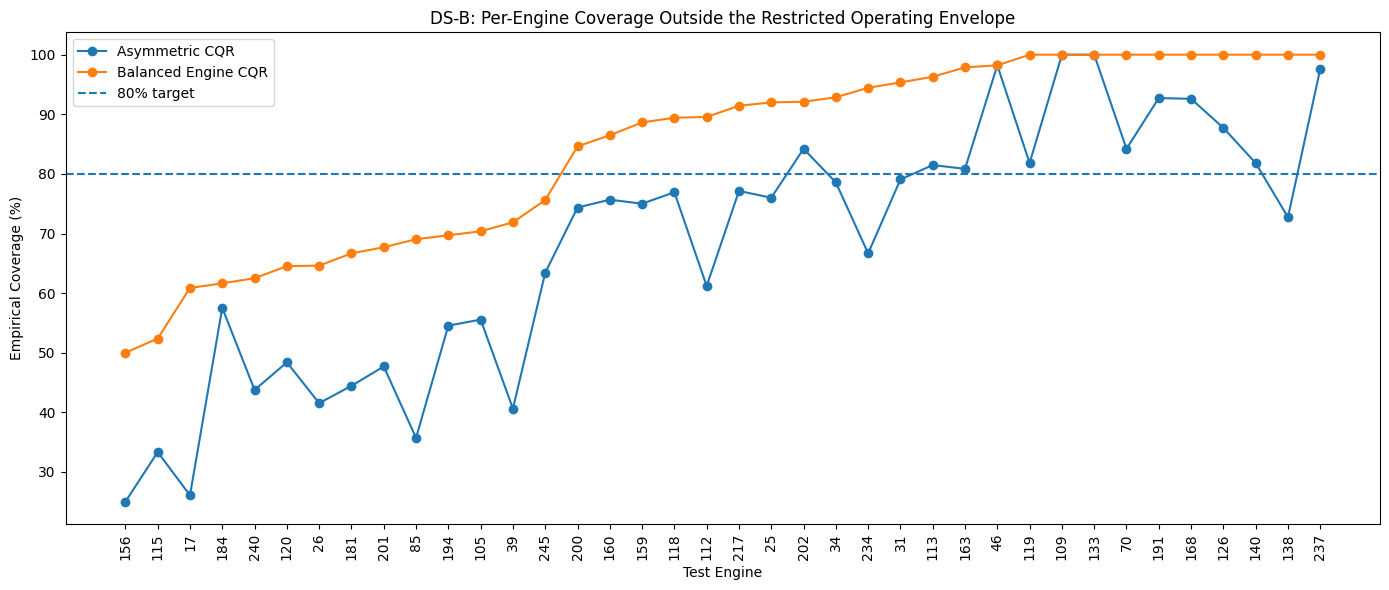

Saved: /content/drive/MyDrive/FD004_DS_B_Results/Figure_DS_B_Per_Engine_Coverage.png


In [31]:
plot_df = (
    engine_results
    .sort_values("Balanced_Coverage")
    .reset_index(drop=True)
)

x = np.arange(len(plot_df))

plt.figure(figsize=(14, 6))

plt.plot(
    x,
    plot_df["Asym_Coverage"],
    marker="o",
    label="Asymmetric CQR"
)

plt.plot(
    x,
    plot_df["Balanced_Coverage"],
    marker="o",
    label="Balanced Engine CQR"
)

plt.axhline(
    80,
    linestyle="--",
    label="80% target"
)

plt.xticks(
    x,
    plot_df["engine_id"],
    rotation=90
)

plt.xlabel("Test Engine")
plt.ylabel("Empirical Coverage (%)")
plt.title(
    "DS-B: Per-Engine Coverage Outside the Restricted Operating Envelope"
)

plt.legend()
plt.tight_layout()

fig_path = os.path.join(
    OUTPUT_DIR,
    "Figure_DS_B_Per_Engine_Coverage.png"
)
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", fig_path)

## 31. Problem engines and error–coverage relationship

In [32]:
problem_engines = (
    engine_results[
        engine_results["Balanced_Coverage"] < 80
    ]
    .sort_values("Balanced_Coverage")
    .copy()
)

print("Problem engines:", len(problem_engines))

display(
    problem_engines[
        [
            "engine_id",
            "n_windows",
            "RMSE",
            "MAE",
            "Asym_Coverage",
            "Balanced_Coverage",
            "Balanced_Width",
            "Mean_Excess_Score"
        ]
    ].round(3)
)

rmse_cov_corr = engine_results[
    ["RMSE", "Balanced_Coverage"]
].corr().iloc[0, 1]

mae_cov_corr = engine_results[
    ["MAE", "Balanced_Coverage"]
].corr().iloc[0, 1]

print(
    f"RMSE vs Balanced coverage correlation: "
    f"{rmse_cov_corr:.3f}"
)

print(
    f"MAE vs Balanced coverage correlation: "
    f"{mae_cov_corr:.3f}"
)

Problem engines: 14


,engine_id,n_windows,RMSE,MAE,Asym_Coverage,Balanced_Coverage,Balanced_Width,Mean_Excess_Score
21,156,20,54.586,49.244,25.000,50.000,71.177002,0.154
13,115,21,54.314,50.793,33.333,52.381,71.526001,0.116
0,17,23,51.729,46.821,26.087,60.870,71.578003,0.205
27,184,73,35.178,22.865,57.534,61.644,65.163002,0.172
36,240,16,50.585,45.314,43.750,62.500,71.154999,0.186
16,120,31,43.472,37.297,48.387,64.516,71.758003,0.186
2,26,65,26.200,19.843,41.538,64.615,68.750999,0.216
26,181,18,40.954,37.216,44.444,66.667,71.497002,0.302
31,201,65,27.969,20.689,47.692,67.692,68.598000,0.195
8,85,42,24.855,21.464,35.714,69.048,69.236000,0.213


RMSE vs Balanced coverage correlation: -0.885
MAE vs Balanced coverage correlation: -0.878


## 32. Figure: point error vs Balanced Engine coverage

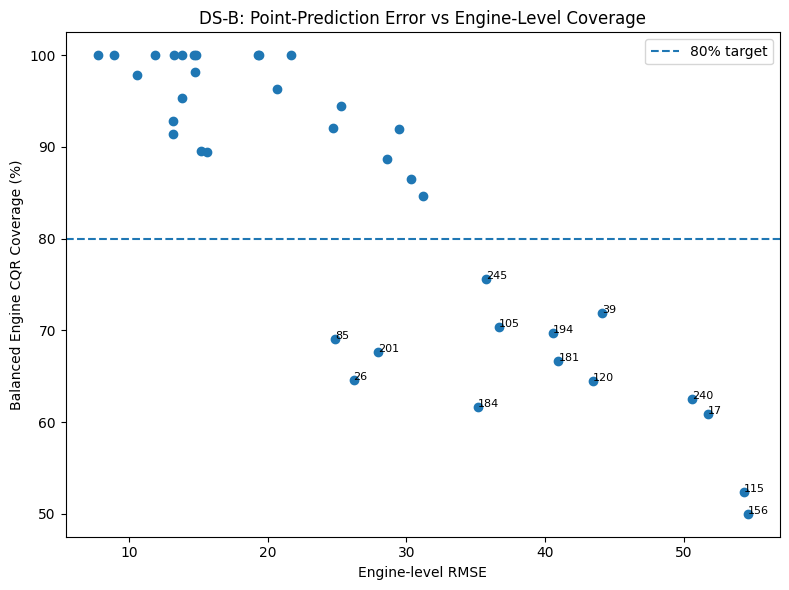

Saved: /content/drive/MyDrive/FD004_DS_B_Results/Figure_DS_B_Error_vs_Coverage.png


In [33]:
plt.figure(figsize=(8, 6))

plt.scatter(
    engine_results["RMSE"],
    engine_results["Balanced_Coverage"]
)

plt.axhline(
    80,
    linestyle="--",
    label="80% target"
)

for _, row in problem_engines.iterrows():
    plt.annotate(
        str(int(row["engine_id"])),
        (
            row["RMSE"],
            row["Balanced_Coverage"]
        ),
        fontsize=8
    )

plt.xlabel("Engine-level RMSE")
plt.ylabel("Balanced Engine CQR Coverage (%)")

plt.title(
    "DS-B: Point-Prediction Error vs Engine-Level Coverage"
)

plt.legend()
plt.tight_layout()

fig_path = os.path.join(
    OUTPUT_DIR,
    "Figure_DS_B_Error_vs_Coverage.png"
)
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", fig_path)

## 33. New DS-B diagnostic: severity of envelope shift vs prediction error/coverage

This directly tests whether moving further outside the training envelope is associated with larger RUL error or weaker interval coverage.

In [34]:
abs_error = np.abs(
    y_test_ds - p50_test
)

excess_score = (
    score_test_endpoint -
    threshold_test_endpoint
)

severity_df = pd.DataFrame({
    "engine_id": ids_test,
    "regime": reg_test_endpoint,
    "RUL": y_test_ds,
    "abs_error": abs_error,
    "envelope_score": score_test_endpoint,
    "threshold": threshold_test_endpoint,
    "excess_score": excess_score,
    "asym_covered": asym_covered.astype(int),
    "balanced_covered": balanced_covered.astype(int)
})

error_severity_corr = severity_df[
    ["excess_score", "abs_error"]
].corr().iloc[0, 1]

coverage_severity_corr = severity_df[
    ["excess_score", "balanced_covered"]
].corr().iloc[0, 1]

print(
    "Excess envelope score vs absolute error:",
    round(error_severity_corr, 3)
)

print(
    "Excess envelope score vs Balanced coverage indicator:",
    round(coverage_severity_corr, 3)
)

display(severity_df.head())

Excess envelope score vs absolute error: 0.011
Excess envelope score vs Balanced coverage indicator: -0.006


,engine_id,regime,RUL,abs_error,envelope_score,threshold,excess_score,asym_covered,balanced_covered
0,17,3,121.0,3.917953,1.093962,1.012712,0.081250,1,1
1,17,2,111.0,13.901848,1.254664,1.009493,0.245171,1,1
2,17,0,101.0,23.370331,1.273047,1.004801,0.268246,1,1
3,17,5,100.0,24.153046,1.109117,1.008762,0.100355,1,1
4,17,4,99.0,25.400978,1.176165,1.018319,0.157845,1,1


## 34. Figure: envelope-shift severity vs absolute prediction error

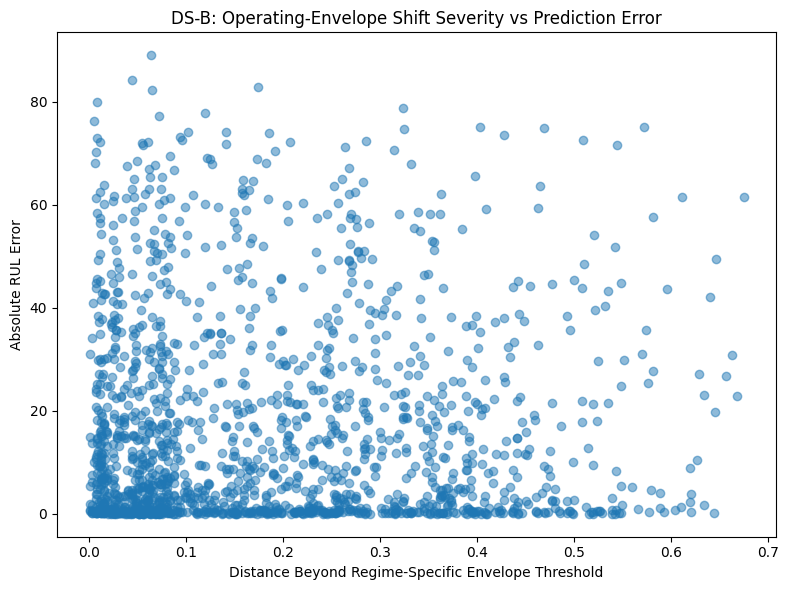

Saved: /content/drive/MyDrive/FD004_DS_B_Results/Figure_DS_B_Shift_Severity_vs_Error.png


In [35]:
plt.figure(figsize=(8, 6))

plt.scatter(
    severity_df["excess_score"],
    severity_df["abs_error"],
    alpha=0.5
)

plt.xlabel("Distance Beyond Regime-Specific Envelope Threshold")
plt.ylabel("Absolute RUL Error")

plt.title(
    "DS-B: Operating-Envelope Shift Severity vs Prediction Error"
)

plt.tight_layout()

fig_path = os.path.join(
    OUTPUT_DIR,
    "Figure_DS_B_Shift_Severity_vs_Error.png"
)
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", fig_path)

## 35. Reliability by operating regime

In [36]:
regime_results = []

for regime in sorted(np.unique(reg_test_endpoint)):

    mask = reg_test_endpoint == regime

    regime_results.append({
        "Regime": int(regime),
        "N_Windows": int(np.sum(mask)),
        "N_Engines": int(len(np.unique(ids_test[mask]))),

        "RMSE": np.sqrt(
            mean_squared_error(
                y_test_ds[mask],
                p50_test[mask]
            )
        ),

        "MAE": mean_absolute_error(
            y_test_ds[mask],
            p50_test[mask]
        ),

        "Asym_Coverage":
            100 * np.mean(asym_covered[mask]),

        "Balanced_Coverage":
            100 * np.mean(balanced_covered[mask]),

        "Asym_Width":
            np.mean(
                asym_upper[mask] -
                asym_lower[mask]
            ),

        "Balanced_Width":
            np.mean(
                balanced_upper[mask] -
                balanced_lower[mask]
            ),

        "Mean_Excess_Score":
            np.mean(excess_score[mask])
    })

regime_results = pd.DataFrame(regime_results)

display(regime_results.round(3))

,Regime,N_Windows,N_Engines,RMSE,MAE,Asym_Coverage,Balanced_Coverage,Asym_Width,Balanced_Width,Mean_Excess_Score
0,0,397,38,25.956,17.095,72.544,86.650,47.471001,69.411003,0.188
1,1,275,38,27.731,18.536,69.091,84.000,47.689999,69.719002,0.175
2,2,244,38,26.016,16.883,73.361,88.525,47.148998,69.142998,0.187
3,3,228,38,25.177,15.341,74.561,84.211,48.035000,70.494003,0.182
4,4,244,38,22.884,15.035,73.361,88.525,48.049000,70.371002,0.186
5,5,235,37,27.424,17.901,67.234,84.255,47.509998,69.522003,0.197


## 36. Figure: DS-B coverage by operating regime

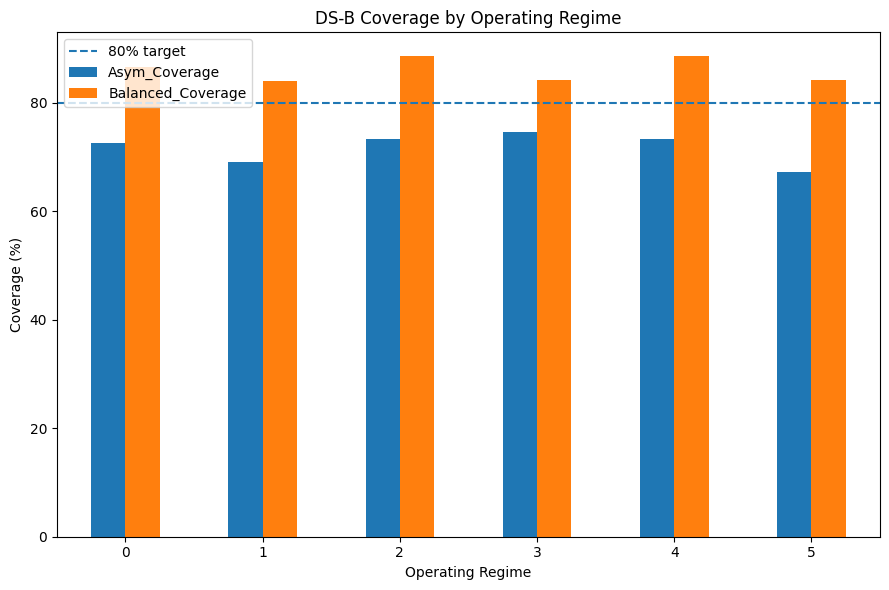

Saved: /content/drive/MyDrive/FD004_DS_B_Results/Figure_DS_B_Coverage_By_Regime.png


In [37]:
plot_regime = regime_results.set_index(
    "Regime"
)[
    [
        "Asym_Coverage",
        "Balanced_Coverage"
    ]
]

ax = plot_regime.plot(
    kind="bar",
    figsize=(9, 6)
)

ax.axhline(
    80,
    linestyle="--",
    label="80% target"
)

ax.set_ylabel("Coverage (%)")
ax.set_xlabel("Operating Regime")
ax.set_title(
    "DS-B Coverage by Operating Regime"
)

plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()

fig_path = os.path.join(
    OUTPUT_DIR,
    "Figure_DS_B_Coverage_By_Regime.png"
)
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", fig_path)

## 37. Life-stage reliability

In [38]:
def assign_life_stage(rul):
    if rul > 80:
        return "Early"
    elif rul > 40:
        return "Mid"
    else:
        return "Late"


life_stage = np.array([
    assign_life_stage(r)
    for r in y_test_ds
])

stage_results = []

for stage in ["Early", "Mid", "Late"]:

    mask = life_stage == stage

    if np.sum(mask) == 0:
        continue

    stage_results.append({
        "Life_Stage": stage,
        "N_Windows": int(np.sum(mask)),

        "RMSE": np.sqrt(
            mean_squared_error(
                y_test_ds[mask],
                p50_test[mask]
            )
        ),

        "MAE": mean_absolute_error(
            y_test_ds[mask],
            p50_test[mask]
        ),

        "Asym_Coverage":
            100 * np.mean(asym_covered[mask]),

        "Balanced_Coverage":
            100 * np.mean(balanced_covered[mask]),

        "Asym_Width":
            np.mean(
                asym_upper[mask] -
                asym_lower[mask]
            ),

        "Balanced_Width":
            np.mean(
                balanced_upper[mask] -
                balanced_lower[mask]
            ),

        "Mean_Excess_Score":
            np.mean(excess_score[mask])
    })

stage_results = pd.DataFrame(stage_results)

display(stage_results.round(3))

,Life_Stage,N_Windows,RMSE,MAE,Asym_Coverage,Balanced_Coverage,Asym_Width,Balanced_Width,Mean_Excess_Score
0,Early,1003,17.529,10.164,81.157,91.027,48.523998,71.774002,0.186
1,Mid,318,42.940,37.312,44.025,66.981,47.978001,70.319000,0.192
2,Late,302,25.644,17.606,69.536,89.735,44.301998,62.351002,0.177


## 38. Figure: DS-B coverage by life stage

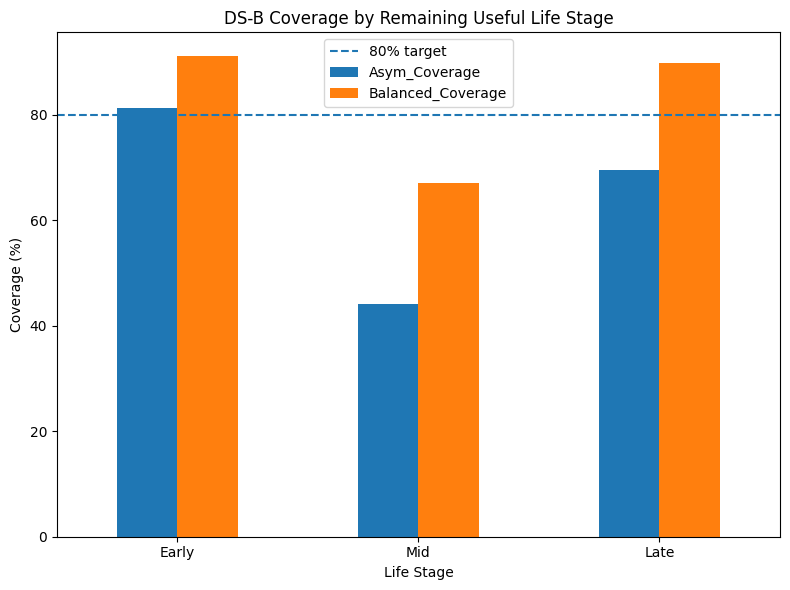

Saved: /content/drive/MyDrive/FD004_DS_B_Results/Figure_DS_B_Life_Stage.png


In [39]:
plot_stage = stage_results.set_index(
    "Life_Stage"
)[
    [
        "Asym_Coverage",
        "Balanced_Coverage"
    ]
]

ax = plot_stage.plot(
    kind="bar",
    figsize=(8, 6)
)

ax.axhline(
    80,
    linestyle="--",
    label="80% target"
)

ax.set_ylabel("Coverage (%)")
ax.set_xlabel("Life Stage")
ax.set_title(
    "DS-B Coverage by Remaining Useful Life Stage"
)

plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()

fig_path = os.path.join(
    OUTPUT_DIR,
    "Figure_DS_B_Life_Stage.png"
)
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", fig_path)

## 39. Problem-engine life-stage analysis

In [40]:
problem_ids = set(
    problem_engines["engine_id"]
)

problem_mask = np.array([
    eng in problem_ids
    for eng in ids_test
])

problem_stage_summary = []

for stage in ["Early", "Mid", "Late"]:

    mask = (
        problem_mask
        & (life_stage == stage)
    )

    if np.sum(mask) == 0:
        continue

    problem_stage_summary.append({
        "Life_Stage": stage,
        "N_Windows": int(np.sum(mask)),

        "RMSE": np.sqrt(
            mean_squared_error(
                y_test_ds[mask],
                p50_test[mask]
            )
        ),

        "Balanced_Coverage":
            100 * np.mean(
                balanced_covered[mask]
            ),

        "Mean_Excess_Score":
            np.mean(excess_score[mask])
    })

problem_stage_summary = pd.DataFrame(
    problem_stage_summary
)

display(problem_stage_summary.round(3))

,Life_Stage,N_Windows,RMSE,Balanced_Coverage,Mean_Excess_Score
0,Early,267,26.861,76.404,0.189
1,Mid,136,53.390,37.500,0.195
2,Late,104,37.931,75.000,0.180


## 40. Trajectory diagnostics for the four worst-covered DS-B engines

The engines are selected automatically from the current DS-B results rather than hard-coded.

Worst engines: [156, 115, 17, 184]


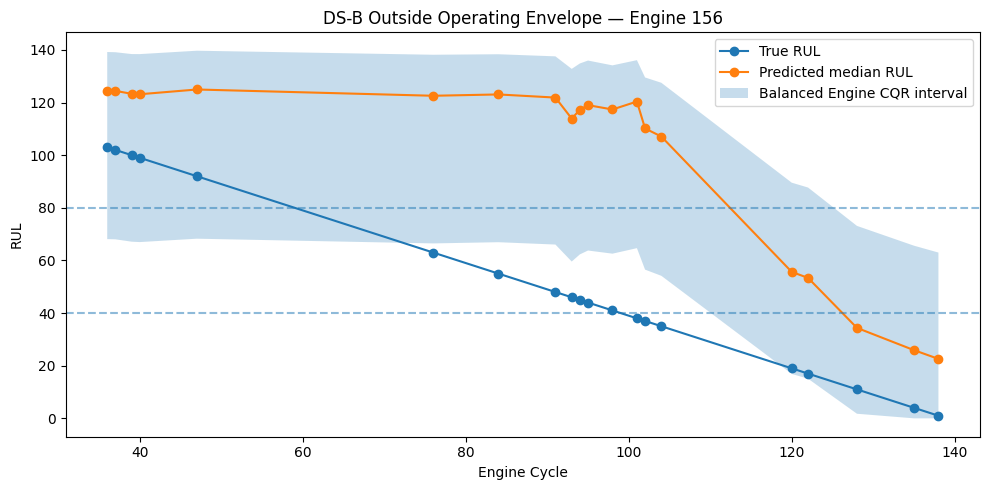

Saved: /content/drive/MyDrive/FD004_DS_B_Results/Figure_DS_B_Trajectory_Engine_156.png


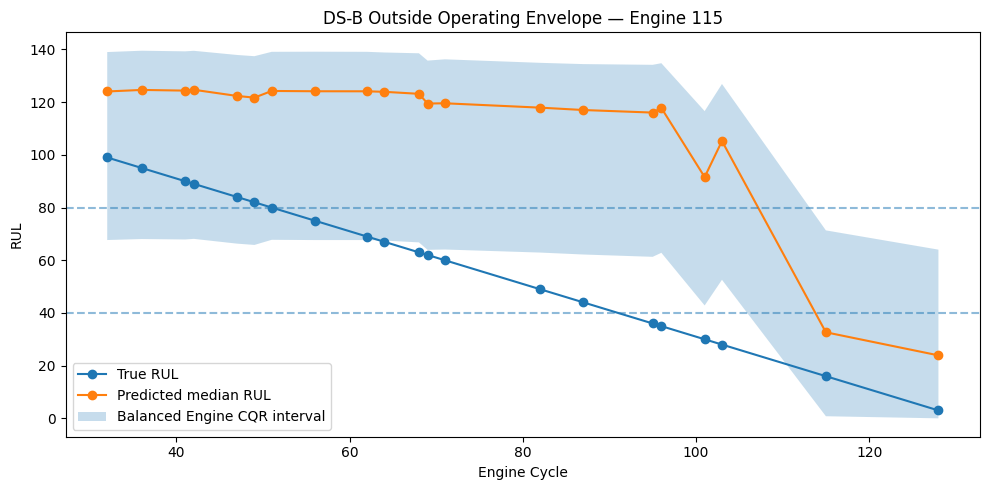

Saved: /content/drive/MyDrive/FD004_DS_B_Results/Figure_DS_B_Trajectory_Engine_115.png


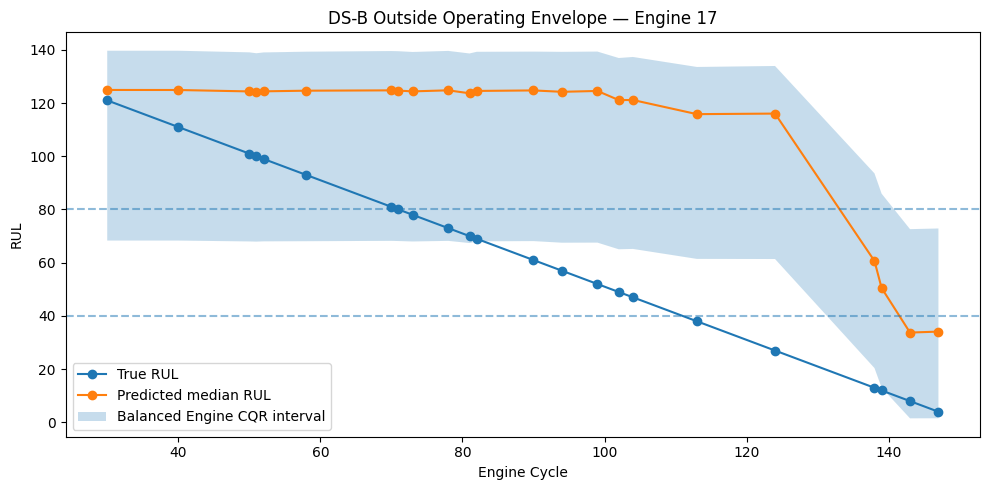

Saved: /content/drive/MyDrive/FD004_DS_B_Results/Figure_DS_B_Trajectory_Engine_17.png


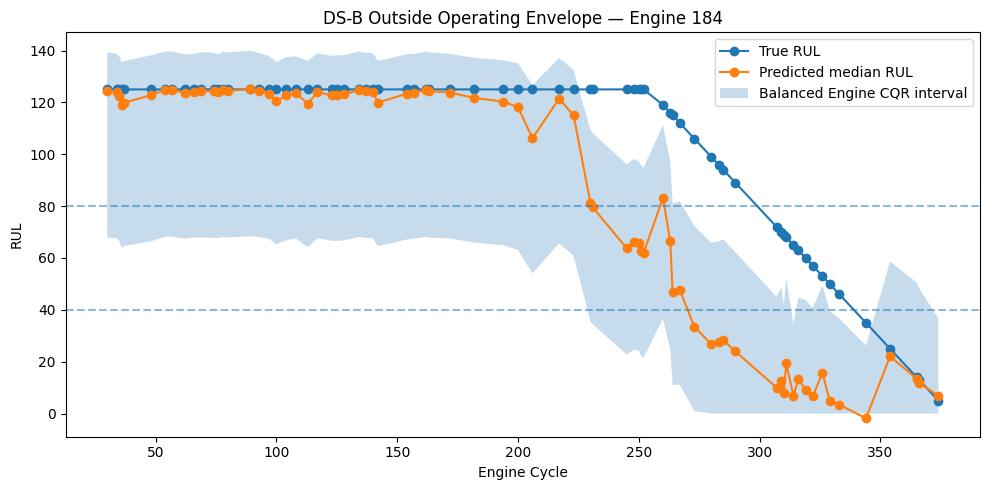

Saved: /content/drive/MyDrive/FD004_DS_B_Results/Figure_DS_B_Trajectory_Engine_184.png


In [41]:
worst_engines = (
    engine_results
    .sort_values("Balanced_Coverage")
    .head(4)["engine_id"]
    .astype(int)
    .tolist()
)

print("Worst engines:", worst_engines)

for eng in worst_engines:

    mask = ids_test == eng
    order = np.argsort(cycles_test[mask])

    cycles_eng = cycles_test[mask][order]
    y_eng = y_test_ds[mask][order]
    pred_eng = p50_test[mask][order]

    lower_eng = balanced_lower[mask][order]
    upper_eng = balanced_upper[mask][order]

    plt.figure(figsize=(10, 5))

    plt.plot(
        cycles_eng,
        y_eng,
        marker="o",
        label="True RUL"
    )

    plt.plot(
        cycles_eng,
        pred_eng,
        marker="o",
        label="Predicted median RUL"
    )

    plt.fill_between(
        cycles_eng,
        lower_eng,
        upper_eng,
        alpha=0.25,
        label="Balanced Engine CQR interval"
    )

    plt.axhline(
        80,
        linestyle="--",
        alpha=0.5
    )

    plt.axhline(
        40,
        linestyle="--",
        alpha=0.5
    )

    plt.xlabel("Engine Cycle")
    plt.ylabel("RUL")
    plt.title(
        f"DS-B Outside Operating Envelope — Engine {eng}"
    )

    plt.legend()
    plt.tight_layout()

    fig_path = os.path.join(
        OUTPUT_DIR,
        f"Figure_DS_B_Trajectory_Engine_{eng}.png"
    )
    plt.savefig(fig_path, dpi=300, bbox_inches="tight")
    plt.show()

    print("Saved:", fig_path)

## 41. Final DS-B summary table

In [42]:
final_ds_b = pd.DataFrame([
    {
        "Metric": "Point RMSE",
        "Value": test_rmse
    },
    {
        "Metric": "Point MAE",
        "Value": test_mae
    },
    {
        "Metric": "Asymmetric CQR Coverage (%)",
        "Value": asym_picp
    },
    {
        "Metric": "Asymmetric Mean Width",
        "Value": asym_mpiw
    },
    {
        "Metric": "Balanced CQR Coverage (%)",
        "Value": balanced_picp
    },
    {
        "Metric": "Balanced Mean Width",
        "Value": balanced_mpiw
    },
    {
        "Metric": "Balanced engines >= 80%",
        "Value": np.sum(
            engine_results["Balanced_Coverage"] >= 80
        )
    },
    {
        "Metric": "Balanced worst-engine coverage (%)",
        "Value": engine_results[
            "Balanced_Coverage"
        ].min()
    },
    {
        "Metric": "RMSE vs Balanced coverage correlation",
        "Value": rmse_cov_corr
    },
    {
        "Metric": "Excess envelope score vs absolute error correlation",
        "Value": error_severity_corr
    }
])

display(final_ds_b.round(3))

,Metric,Value
0,Point RMSE,25.952
1,Point MAE,16.868
2,Asymmetric CQR Coverage (%),71.719
3,Asymmetric Mean Width,47.631
4,Balanced CQR Coverage (%),86.075
5,Balanced Mean Width,69.735
6,Balanced engines >= 80%,24.000
7,Balanced worst-engine coverage (%),50.000
8,RMSE vs Balanced coverage correlation,-0.885
9,Excess envelope score vs absolute error correl...,0.011


## 42. Export all final DS-B tables

In [43]:
ds_b_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "DS_B_Global_Summary.csv"
    ),
    index=False
)

engine_results.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "DS_B_Engine_Reliability.csv"
    ),
    index=False
)

problem_engines.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "DS_B_Problem_Engines.csv"
    ),
    index=False
)

regime_results.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "DS_B_Regime_Results.csv"
    ),
    index=False
)

stage_results.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "DS_B_Life_Stage_Results.csv"
    ),
    index=False
)

problem_stage_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "DS_B_Problem_Engine_Life_Stage.csv"
    ),
    index=False
)

severity_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "DS_B_Envelope_Severity_Diagnostics.csv"
    ),
    index=False
)

final_ds_b.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "DS_B_Final_Summary.csv"
    ),
    index=False
)

availability.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "DS_B_Envelope_Availability.csv"
    ),
    index=False
)

print("✓ Final DS-B CSV tables exported.")

✓ Final DS-B CSV tables exported.


## 43. Save model, split definition and configuration

In [44]:
model_path = os.path.join(
    OUTPUT_DIR,
    "FD004_DS_B_Model.keras"
)

model.save(model_path)

split_rows = []

for split_name, engines in [
    ("train", train_engines),
    ("calibration", cal_engines),
    ("test", test_engines)
]:
    for eng in engines:
        split_rows.append({
            "split": split_name,
            "unit_id": int(eng)
        })

split_definition = pd.DataFrame(split_rows)

split_definition.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "DS_B_Engine_Split.csv"
    ),
    index=False
)

threshold_df = pd.DataFrame({
    "regime": list(regime_thresholds.keys()),
    "envelope_threshold": list(regime_thresholds.values())
}).sort_values("regime")

threshold_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "DS_B_Regime_Envelope_Thresholds.csv"
    ),
    index=False
)

config = {
    "experiment": "FD004_DS_B_Restricted_Operating_Envelope",
    "seed": SEED,
    "rul_clip": RUL_CLIP,
    "window_size": WINDOW_SIZE,
    "n_regimes": N_REGIMES,
    "envelope_quantile": ENVELOPE_QUANTILE,
    "selected_sensors": SELECTED_SENSORS,
    "operating_settings": OPERATING_SETTINGS,
    "alpha": ALPHA,
    "quantiles": QUANTILES,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "endpoint_rule": {
        "train": "inside regime-specific central envelope",
        "calibration": "inside regime-specific central envelope",
        "test": "outside regime-specific central envelope"
    }
}

with open(
    os.path.join(
        OUTPUT_DIR,
        "DS_B_Config.json"
    ),
    "w"
) as f:
    json.dump(config, f, indent=2)

print("✓ Model saved:", model_path)
print("✓ Split definition saved.")
print("✓ Envelope thresholds saved.")
print("✓ Configuration saved.")

✓ Model saved: /content/drive/MyDrive/FD004_DS_B_Results/FD004_DS_B_Model.keras
✓ Split definition saved.
✓ Envelope thresholds saved.
✓ Configuration saved.


# 44. Interpretation checklist

After running the notebook, record the following before changing anything:

- [ ] DS-B point RMSE and MAE
- [ ] Asymmetric CQR coverage and mean width
- [ ] Balanced Engine CQR coverage and mean width
- [ ] Number of engines reaching ≥80% coverage for each method
- [ ] Worst-engine coverage
- [ ] RMSE–coverage correlation
- [ ] Coverage by life stage
- [ ] Coverage by operating regime
- [ ] Correlation between distance beyond the envelope and absolute RUL error
- [ ] Whether the same engines that failed in DS-A also fail in DS-B
- [ ] Whether mid-life remains the dominant failure region

## Paper 1 comparison to make after DS-B
Compare:
1. Standard/IID final Paper 1 results
2. DS-A held-out-regime shift
3. DS-B restricted operating-envelope shift

The main research question is:

> Does the engine-balanced conformal method remain more reliable than efficiency-oriented asymmetric CQR under two distinct forms of operating-condition distribution shift, and are residual failures explained primarily by point-model degradation rather than calibration alone?

Do **not** tune DS-B after seeing the test results. Any alternative envelope quantile should be reported as a pre-declared sensitivity analysis, not substituted for the primary 80th-percentile experiment.


---

# Paper 1 fixed-spec five-seed UQ confirmation

**Purpose:** confirm stochastic stability of the already-frozen Paper 1 uncertainty results.

**Seeds:** 42, 123, 456, 789, 1000.

**Frozen choices:** no architecture selection, no hyperparameter tuning, no split changes, no calibration-rule changes, no DS-A/DS-B threshold changes. The final quantile model uses 25 epochs, batch size 64, Adam 1e-3, the 20→18 linear projection, BiLSTM(64 each direction), temporal attention, and q10/q50/q90 pinball loss.

**Methods reported:** Asymmetric CQR and Balanced Engine CQR.

**Metrics:** PICP, MPIW, Winkler score, point RMSE/MAE, calibration corrections. Outputs are written per seed and as mean ± sample SD.

**Quantile convention preserved from the frozen notebooks:** finite-sample conformal quantiles use `method="higher"`. The first-stage within-engine 0.80 quantile in Balanced Engine CQR intentionally uses NumPy's default interpolation, matching the frozen implementation; the second-stage across-engine conformal quantile uses `method="higher"`.

Seed 42 is treated as a reproducibility check against the frozen master result. A mismatch is a warning to stop and resolve the runtime/data specification before using the multi-seed summary.


## DS-B confirmatory section
Run the original notebook through preprocessing/window construction so the frozen `X_train_ds`, `y_train_ds`, `X_cal_ds`, `y_cal_ds`, `ids_cal`, `X_test_ds`, and `y_test_ds` arrays exist. Then run the cells below. The confirmatory loop builds fresh models for all five seeds; it does not use the original seed-42 trained model.

In [45]:

import os, random, time, gc
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import mean_squared_error, mean_absolute_error
from tensorflow.keras.layers import Input, LSTM, Bidirectional, Dense, Layer
from tensorflow.keras.models import Model

SEEDS = [42, 123, 456, 789, 1000]
ALPHA = 0.20
QUANTILES = [0.10, 0.50, 0.90]
EPOCHS = 25
BATCH_SIZE = 64

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

def conformal_quantile(scores, alpha):
    scores = np.asarray(scores)
    n = len(scores)
    q_level = min(1.0, np.ceil((n + 1) * (1 - alpha)) / n)
    return float(np.quantile(scores, q_level, method="higher"))

def interval_metrics(y, lo, hi, alpha=ALPHA):
    y = np.asarray(y)
    lo = np.asarray(lo)
    hi = np.asarray(hi)
    covered = (y >= lo) & (y <= hi)
    width = hi - lo
    winkler = (
        width
        + (2.0 / alpha) * (lo - y) * (y < lo)
        + (2.0 / alpha) * (y - hi) * (y > hi)
    )
    return {
        "PICP": 100.0 * covered.mean(),
        "MPIW": width.mean(),
        "Winkler": winkler.mean(),
    }

def summarize_seed_table(df):
    numeric_cols = [
        c for c in df.columns
        if c not in ("Condition", "Method", "Seed")
        and pd.api.types.is_numeric_dtype(df[c])
    ]
    rows = []
    for (condition, method), g in df.groupby(["Condition","Method"], sort=False):
        row = {"Condition": condition, "Method": method, "N_Seeds": len(g)}
        for c in numeric_cols:
            row[c + "_mean"] = g[c].mean()
            row[c + "_sd"] = g[c].std(ddof=1)
        rows.append(row)
    return pd.DataFrame(rows)

def out_dir():
    drive_dir = "/content/drive/MyDrive/FD004_Research/Paper1_MultiSeed_UQ"
    if os.path.isdir("/content/drive/MyDrive"):
        os.makedirs(drive_dir, exist_ok=True)
        return drive_dir
    local = "/content/Paper1_MultiSeed_UQ"
    os.makedirs(local, exist_ok=True)
    return local

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
print("Output directory:", out_dir())


TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Output directory: /content/drive/MyDrive/FD004_Research/Paper1_MultiSeed_UQ


In [46]:

required = ["X_train_ds","y_train_ds","X_cal_ds","y_cal_ds","ids_cal","X_test_ds","y_test_ds"]
missing = [v for v in required if v not in globals()]
if missing:
    raise RuntimeError(
        "Missing frozen preprocessed arrays: " + ", ".join(missing) +
        "\nRun the original notebook through data preparation/window construction first."
    )
assert X_train_ds.shape[-1] == 20
assert X_cal_ds.shape[-1] == 20
assert X_test_ds.shape[-1] == 20
print("Train:", X_train_ds.shape, "Cal:", X_cal_ds.shape, "Test:", X_test_ds.shape)
print("Calibration engines:", len(np.unique(ids_cal)))


Train: (30254, 30, 20) Cal: (6402, 30, 20) Test: (1623, 30, 20)
Calibration engines: 37


In [47]:

class ConfirmatoryAttention(Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
    def build(self, input_shape):
        dim = input_shape[-1]
        self.W = self.add_weight(name="W", shape=(dim, dim), initializer="glorot_uniform", trainable=True)
        self.b = self.add_weight(name="b", shape=(dim,), initializer="zeros", trainable=True)
        self.v = self.add_weight(name="v", shape=(dim, 1), initializer="glorot_uniform", trainable=True)
        super().build(input_shape)
    def call(self, inputs):
        e = tf.nn.tanh(tf.tensordot(inputs, self.W, axes=1) + self.b)
        scores = tf.tensordot(e, self.v, axes=1)
        weights = tf.nn.softmax(scores, axis=1)
        return tf.reduce_sum(inputs * weights, axis=1)

def tilted_loss_confirm(q, y_true, y_pred):
    error = y_true - y_pred
    return tf.maximum(q * error, (q - 1.0) * error)

def loss_confirm(y_true, y_pred):
    y_true = tf.cast(tf.reshape(y_true, (-1,1)), tf.float32)
    return tf.reduce_mean(tf.add_n([
        tilted_loss_confirm(q, y_true, y_pred[:,i:i+1])
        for i,q in enumerate(QUANTILES)
    ]))

def build_confirmatory_model():
    inputs = Input(shape=(30,20), name="input_window")
    projection = Dense(18, use_bias=False, name="projection")(inputs)
    lstm_output = Bidirectional(LSTM(64, return_sequences=True), name="bilstm")(projection)
    context = ConfirmatoryAttention(name="temporal_attention")(lstm_output)
    outputs = Dense(3, activation="linear", name="quantiles")(context)
    model = Model(inputs, outputs, name="Paper1_FiveSeed_Confirmatory")
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=loss_confirm)
    return model


In [48]:

CONDITION = "DS-B"
records = []
for run_i, seed in enumerate(SEEDS,1):
    print(f"\n[{run_i}/{len(SEEDS)}] {CONDITION} seed {seed}")
    tf.keras.backend.clear_session()
    gc.collect()
    set_seed(seed)
    model_ms = build_confirmatory_model()
    model_ms.fit(
        X_train_ds, y_train_ds,
        epochs=EPOCHS, batch_size=BATCH_SIZE,
        verbose=2, shuffle=True
    )

    cal_pred = model_ms.predict(X_cal_ds, batch_size=512, verbose=0)
    test_pred = model_ms.predict(X_test_ds, batch_size=512, verbose=0)
    p10c,p50c,p90c = cal_pred[:,0],cal_pred[:,1],cal_pred[:,2]
    p10,p50,p90 = test_pred[:,0],test_pred[:,1],test_pred[:,2]

    # Frozen Asymmetric CQR.
    q_lo = conformal_quantile(p10c - y_cal_ds, ALPHA/2)
    q_hi = conformal_quantile(y_cal_ds - p90c, ALPHA/2)
    lo_a = np.maximum(0.0, p10 - q_lo)
    hi_a = np.maximum(0.0, p90 + q_hi)

    # Frozen Balanced Engine CQR.
    cal_err = np.maximum(p10c - y_cal_ds, y_cal_ds - p90c)
    cal_engines_local = np.unique(ids_cal)
    eng_q80 = np.asarray([
        np.quantile(cal_err[ids_cal == eng], 0.80)
        for eng in cal_engines_local
    ])
    n_eng = len(cal_engines_local)
    q_level_eng = min(1.0, np.ceil((n_eng + 1) * (1 - ALPHA)) / n_eng)
    q_bal = float(np.quantile(eng_q80, q_level_eng, method="higher"))
    lo_b = np.maximum(0.0, p10 - q_bal)
    hi_b = np.maximum(0.0, p90 + q_bal)

    rmse = float(np.sqrt(mean_squared_error(y_test_ds, p50)))
    mae = float(mean_absolute_error(y_test_ds, p50))

    for method,lo,hi,qa,qb in [
        ("Asymmetric CQR",lo_a,hi_a,q_lo,q_hi),
        ("Balanced Engine CQR",lo_b,hi_b,q_bal,q_bal)
    ]:
        met = interval_metrics(y_test_ds, lo, hi)
        records.append({
            "Condition":CONDITION,"Seed":seed,"Method":method,
            "PICP":met["PICP"],"MPIW":met["MPIW"],"Winkler":met["Winkler"],
            "RMSE":rmse,"MAE":mae,"Q_lower":qa,"Q_upper":qb
        })
    print(pd.DataFrame(records[-2:])[["Seed","Method","PICP","MPIW","Winkler","RMSE"]].round(3).to_string(index=False))

seed_df = pd.DataFrame(records)
summary_df = summarize_seed_table(seed_df)

od = out_dir()
slug = CONDITION.replace("-","_")
seed_df.to_csv(os.path.join(od, f"Paper1_FiveSeed_{slug}_per_seed.csv"), index=False)
summary_df.to_csv(os.path.join(od, f"Paper1_FiveSeed_{slug}_summary.csv"), index=False)
display(seed_df.round(3))
display(summary_df.round(3))
print("Saved outputs to", od)



[1/5] DS-B seed 42
Epoch 1/25
473/473 - 9s - 20ms/step - loss: 85.3751
Epoch 2/25
473/473 - 4s - 9ms/step - loss: 42.4404
Epoch 3/25
473/473 - 4s - 9ms/step - loss: 29.3158
Epoch 4/25
473/473 - 5s - 11ms/step - loss: 28.9589
Epoch 5/25
473/473 - 4s - 9ms/step - loss: 28.9446
Epoch 6/25
473/473 - 4s - 9ms/step - loss: 24.6430
Epoch 7/25
473/473 - 5s - 11ms/step - loss: 17.2474
Epoch 8/25
473/473 - 4s - 9ms/step - loss: 14.8721
Epoch 9/25
473/473 - 4s - 8ms/step - loss: 13.6145
Epoch 10/25
473/473 - 5s - 12ms/step - loss: 13.0433
Epoch 11/25
473/473 - 4s - 9ms/step - loss: 12.6773
Epoch 12/25
473/473 - 4s - 9ms/step - loss: 12.4428
Epoch 13/25
473/473 - 5s - 12ms/step - loss: 12.1077
Epoch 14/25
473/473 - 4s - 9ms/step - loss: 11.7542
Epoch 15/25
473/473 - 4s - 9ms/step - loss: 11.3866
Epoch 16/25
473/473 - 5s - 12ms/step - loss: 11.0869
Epoch 17/25
473/473 - 10s - 21ms/step - loss: 10.8367
Epoch 18/25
473/473 - 5s - 11ms/step - loss: 10.6243
Epoch 19/25
473/473 - 4s - 9ms/step - loss: 

,Condition,Seed,Method,PICP,MPIW,Winkler,RMSE,MAE,Q_lower,Q_upper
0,DS-B,42,Asymmetric CQR,77.018,40.334999,75.027000,23.645,14.731,5.446,2.225
1,DS-B,42,Balanced Engine CQR,90.511,68.779999,82.785004,23.645,14.731,18.621,18.621
2,DS-B,123,Asymmetric CQR,74.492,48.554001,84.864998,25.571,16.947,5.477,0.197
3,DS-B,123,Balanced Engine CQR,88.848,74.208000,88.170998,25.571,16.947,16.238,16.238
4,DS-B,456,Asymmetric CQR,74.923,38.601002,71.042000,23.336,14.864,4.466,0.246
5,DS-B,456,Balanced Engine CQR,86.753,54.743000,73.246002,23.336,14.864,10.603,10.603
6,DS-B,789,Asymmetric CQR,78.127,39.082001,67.694000,22.793,14.541,3.576,0.169
7,DS-B,789,Balanced Engine CQR,91.805,63.270000,75.217003,22.793,14.541,14.372,14.372
8,DS-B,1000,Asymmetric CQR,73.691,36.587002,74.955002,23.308,15.018,-1.040,0.055
9,DS-B,1000,Balanced Engine CQR,87.123,57.520000,76.153999,23.308,15.018,10.308,10.308


,Condition,Method,N_Seeds,PICP_mean,PICP_sd,MPIW_mean,MPIW_sd,Winkler_mean,Winkler_sd,RMSE_mean,RMSE_sd,MAE_mean,MAE_sd,Q_lower_mean,Q_lower_sd,Q_upper_mean,Q_upper_sd
0,DS-B,Asymmetric CQR,5,75.650,1.852,40.632000,4.630,74.717003,6.441,23.731,1.074,15.22,0.981,3.585,2.702,0.578,0.923
1,DS-B,Balanced Engine CQR,5,89.008,2.165,63.703999,7.982,79.114998,6.202,23.731,1.074,15.22,0.981,14.028,3.594,14.028,3.594


Saved outputs to /content/drive/MyDrive/FD004_Research/Paper1_MultiSeed_UQ


In [49]:

# Seed-42 reproduction gate against frozen Paper 1 master.
expected_rmse = 23.999
expected = {'rmse': 23.999, 'Asymmetric CQR': {'PICP': 75.97, 'MPIW': 45.325}, 'Balanced Engine CQR': {'PICP': 90.635, 'MPIW': 70.252}}
tols = {"RMSE":0.75,"PICP":0.75,"MPIW":1.50}

s42 = seed_df[seed_df["Seed"] == 42].set_index("Method")
rows = []
for method in ["Asymmetric CQR","Balanced Engine CQR"]:
    row = {"Method":method}
    rmse_obs = float(s42.loc[method,"RMSE"])
    row["RMSE_observed"] = rmse_obs
    row["RMSE_expected"] = expected_rmse
    row["RMSE_PASS"] = abs(rmse_obs-expected_rmse) <= tols["RMSE"]
    ok = row["RMSE_PASS"]
    for metric in ["PICP","MPIW"]:
        obs = float(s42.loc[method,metric])
        exp = expected[method][metric]
        passed = abs(obs-exp) <= tols[metric]
        row[metric+"_observed"] = obs
        row[metric+"_expected"] = exp
        row[metric+"_PASS"] = passed
        ok &= passed
    row["Overall_PASS"] = ok
    rows.append(row)

gate = pd.DataFrame(rows)
display(gate)
gate.to_csv(os.path.join(out_dir(), f"Paper1_FiveSeed_DS_B_seed42_gate.csv"), index=False)
if not bool(gate["Overall_PASS"].all()):
    print("STOP: seed-42 reproduction gate failed. Do not use this multi-seed summary until the frozen runtime specification is reconciled.")
else:
    print("PASS: seed-42 reproduction gate passed.")


,Method,RMSE_observed,RMSE_expected,RMSE_PASS,PICP_observed,PICP_expected,PICP_PASS,MPIW_observed,MPIW_expected,MPIW_PASS,Overall_PASS
0,Asymmetric CQR,23.644998,23.999,True,77.017868,75.970,False,40.334755,45.325,False,False
1,Balanced Engine CQR,23.644998,23.999,True,90.511399,90.635,True,68.780289,70.252,True,True


STOP: seed-42 reproduction gate failed. Do not use this multi-seed summary until the frozen runtime specification is reconciled.
